# Image formation through a diffuser: in situ training of the object arm

Digital twin of the bench. The object pattern $X_O=e^{j\theta}$ is trained in situ so that the intensity behind the
diffuser forms a target image. As for focusing (`Focusing.ipynb`), every iteration measures the complex field
$\hat O$ from one hologram, forms the error field $W = g\odot\hat O$ from it and carries $W$ back to the SLM with an
adjoint, either the physical model fitted from ten probes or a transmission matrix (TM) from $3N = 3{,}072$ patterns.

| Section | In the manuscript |
|---|---|
| 1 · Bench, physical model and TM | Eqs. (4)–(5); Supplementary Notes 3A, 3C |
| 2 · Targets and loss | Supplementary Note 3B, Eq. (S13) |
| 3 · In situ image formation, model vs TM | Fig. 2e,f; Supplementary Notes 3B–C, Table S2 |
| 4 · A stored TM ages; the model is refitted from ten probes | Supplementary Note 3C; Methods |
| 5 · Training while the diffuser drifts slowly | Fig. 4a–d; Methods; Supplementary Note 5A |

Targets are the yin-yang and the clock tower used on the bench (`../data/imaging_targets.npz`, 128 × 128 camera
pixels), low-passed to the $43\times43$-sample window of the twin, and a grating. The optics and methods are in
[`twin.py`](twin.py); every run is saved as a GIF in `gifs/`. Runtime about 4 min on a laptop CPU.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import twin as tw

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9})
os.makedirs("gifs", exist_ok=True)
T_START = time.time()

## 1 · Bench, physical model and TM

The imaging bench is brighter than the focusing bench (reference 1,000, object 10 counts per pixel). The physical model
fits the screen $D$ of $T_O \cong P_{z_s}\mathrm{diag}(D)P_{-z_s}F$ to ten probe fields (Eq. 5); the TM is measured from
3,072 random patterns and initialised from the model. Both are scored by their model accuracy on 40 held-out patterns
inside the image window (Supplementary Note 3C: 0.90 and 0.95 on the bench).

In [2]:
bench = tw.Bench("imaging", seed=0)
rng = np.random.default_rng(7)
X_held = tw.random_patterns(rng, 40)
Y_held = bench.read(X_held, 10)

X_probe = tw.random_patterns(rng, 10)
Y_probe = bench.read(X_probe, 5)
model = tw.fit_screen(X_probe, Y_probe)
t0 = time.time()
tm = tw.measure_tm(bench, rng, 3072, seed_arm=model)[0]
adjoints = {"model": model, "TM": tm}
for name, arm in adjoints.items():
    print(f"{name:5s} model accuracy on the window: {tw.model_accuracy(arm, X_held, Y_held, tw.WIN):.3f}")
print(f"(TM acquisition: {time.time() - t0:.0f} s of simulation)")

model model accuracy on the window: 0.858
TM    model accuracy on the window: 0.994
(TM acquisition: 79 s of simulation)


## 2 · Targets and loss

The loss is the energy-normalised squared error between the measured intensity and the target $T$, insensitive to the
overall brightness,

$$L = \big\langle (s|\hat O|^2 - T)^2\big\rangle,\qquad s = \frac{\sum T}{\sum |\hat O|^2},\qquad\text{(Eq. S13)}$$

and the image quality is $\mathrm{PSNR} = 10\log_{10}(1/\mathrm{MSE})$ of the energy-normalised intensity against the
target (peak 1). The final pattern is read ten times; as in the manuscript we give the PSNR of the **mean image** of the
ten reads and, per frame, the mean ± s.e.m. of the ten single-read PSNRs.

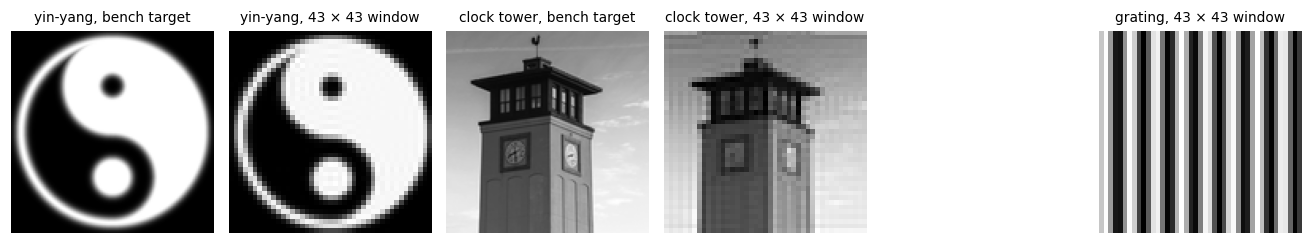

In [3]:
bench_targets = np.load(os.path.join("..", "data", "imaging_targets.npz"))
targets = {"yin-yang": tw.resample_target(bench_targets["yinyang"]),
           "clock tower": tw.resample_target(bench_targets["clock_tower"]),
           "grating": tw.grating_target()}
fig, axs = plt.subplots(1, 6, figsize=(12, 2.2))
for i, (name, t) in enumerate(targets.items()):
    if name in ("yin-yang", "clock tower"):
        axs[2 * i].imshow(bench_targets["yinyang" if name == "yin-yang" else "clock_tower"], cmap="gray")
        axs[2 * i].set_title(f"{name}, bench target")
    axs[2 * i + 1].imshow(t, cmap="gray"); axs[2 * i + 1].set_title(f"{name}, 43 × 43 window")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

## 3 · In situ image formation: physical model vs TM

300 Adam iterations (learning rate 0.1 → 0.03 over the first 100), one SLM pattern of five exposures per iteration
(`tw.train_in_situ`). Both loops use the same measured error field; only the adjoint differs. In each GIF the
measured intensity is energy-normalised to the target, and the grey curve is the other adjoint.

In [4]:
ITERS = 300


def form_image(arm, target):
    # one in situ run; PSNR of the mean image and per frame of the ten final reads
    r = tw.train_in_situ(bench, arm, lambda I: tw.image_loss(I, target), lambda I: tw.psnr(I[tw.WIN], target),
                         iters=ITERS)
    frames = np.array([tw.crop_to(I, tw.WIN) for I in r["finals"]])
    r["psnr_frames"] = np.array([tw.psnr(I, target) for I in frames])
    r["mean_image"] = frames.mean(0)
    r["psnr_mean"] = tw.psnr(r["mean_image"], target)
    r["snaps"] = r["snaps"] * target.sum() / r["snaps"].sum(axis=(1, 2), keepdims=True)    # energy-normalised
    return r


def report(runs, prefix):
    # print the PSNRs and save one GIF per run (shown in the next cell), with the other adjoint's curve in grey
    for (tname, aname), r in runs.items():
        print(f"{tname:12s} {aname:15s} PSNR: mean image {r['psnr_mean']:5.2f} dB, per frame "
              f"{r['psnr_frames'].mean():5.2f} ± {r['psnr_frames'].std() / np.sqrt(10):.2f} dB")
    for (tname, aname), r in runs.items():
        other = [a for t, a in runs if t == tname and a != aname][0]
        path = f"gifs/{prefix}_{tname.replace(' ', '_')}_{aname.replace(' ', '_')}.gif"
        tw.save_gif(path, r["snaps"], r["curve"], "PSNR (dB)", f"{tname}, adjoint: {aname}", own_scale=False,
                    extra_curves={other: runs[tname, other]["curve"]})


runs = {(tname, aname): form_image(arm, target) for tname, target in targets.items() for aname, arm in adjoints.items()}
report(runs, "imaging")

yin-yang     model           PSNR: mean image 17.77 dB, per frame 15.20 ± 0.15 dB
yin-yang     TM              PSNR: mean image 18.16 dB, per frame 15.28 ± 0.17 dB
clock tower  model           PSNR: mean image 17.73 dB, per frame 15.19 ± 0.10 dB
clock tower  TM              PSNR: mean image 18.26 dB, per frame 15.45 ± 0.12 dB
grating      model           PSNR: mean image 21.15 dB, per frame 16.90 ± 0.18 dB
grating      TM              PSNR: mean image 21.85 dB, per frame 16.96 ± 0.18 dB


**GIFs of the runs** (files in `gifs/`, linked rather than embedded to keep the notebook small; one frame per iteration):

| target | model | TM |
|---|---|---|
| yin-yang | ![yin-yang, model](gifs/imaging_yin-yang_model.gif) | ![yin-yang, TM](gifs/imaging_yin-yang_TM.gif) |
| clock tower | ![clock tower, model](gifs/imaging_clock_tower_model.gif) | ![clock tower, TM](gifs/imaging_clock_tower_TM.gif) |
| grating | ![grating, model](gifs/imaging_grating_model.gif) | ![grating, TM](gifs/imaging_grating_TM.gif) |

## Results

Rows: targets. Columns: target, mean image of the ten final reads with each adjoint, PSNR per iteration (cf. Fig. 2e,f).

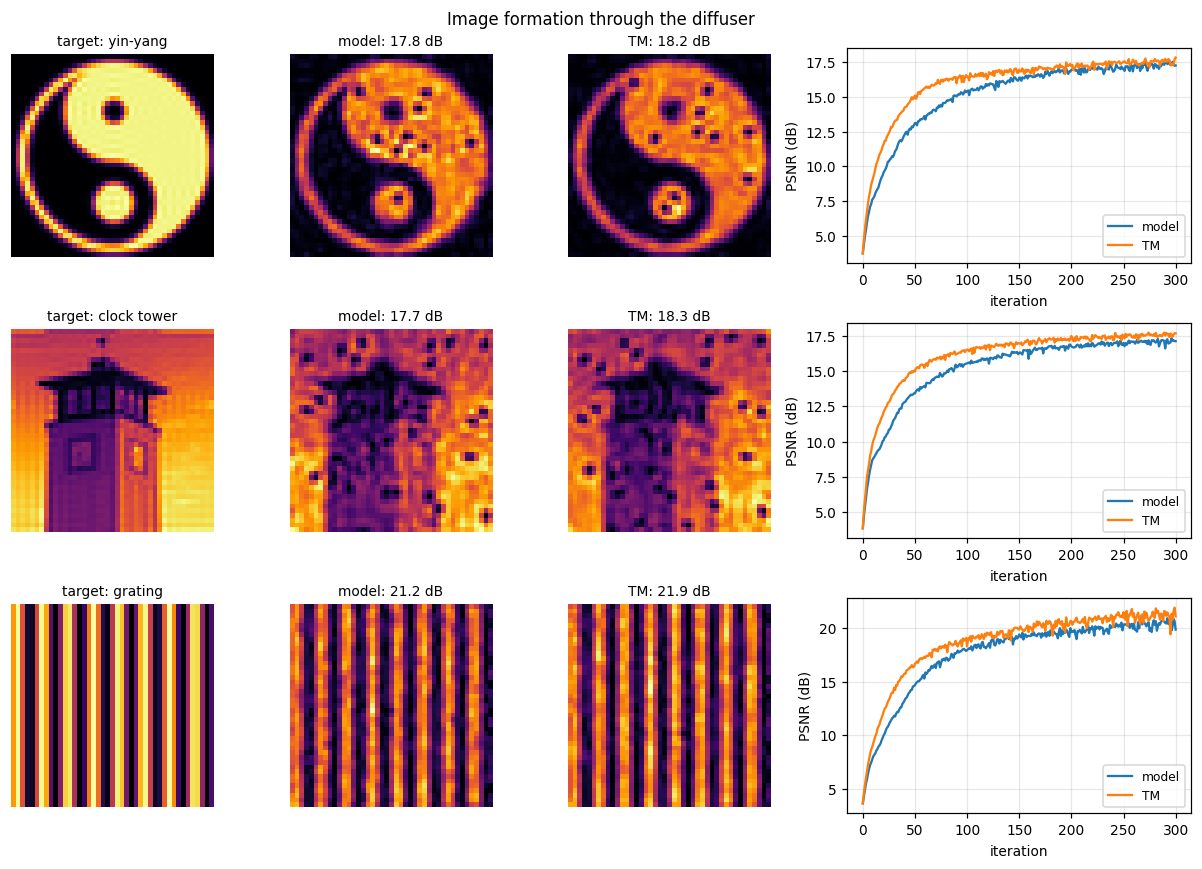

In [5]:
def plot_results(res, adjoint_names, title):
    fig, axs = plt.subplots(3, 4, figsize=(11, 8), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.7]))
    for row, (tname, target) in enumerate(targets.items()):
        axs[row, 0].imshow(target, cmap="inferno"); axs[row, 0].set_title(f"target: {tname}")
        for col, aname in enumerate(adjoint_names, start=1):
            r = res[tname, aname]
            axs[row, col].imshow(r["mean_image"], cmap="inferno")
            axs[row, col].set_title(f"{aname}: {r['psnr_mean']:.1f} dB")
            axs[row, 3].plot(r["curve"], label=aname)
        axs[row, 3].set_xlabel("iteration"); axs[row, 3].set_ylabel("PSNR (dB)")
        axs[row, 3].grid(alpha=0.3); axs[row, 3].legend(fontsize=8, loc="lower right")
        for a in axs[row, :3]: a.axis("off")
    fig.suptitle(title)
    plt.tight_layout(); plt.show()


plot_results(runs, adjoints, "Image formation through the diffuser")

## 4 · A stored TM ages; the model is refitted from ten probes

As in `Focusing.ipynb`, the diffuser is now moved sideways by 50 µm, close to its 60 µm correlation length, hidden from
both methods. Re-measuring the TM would cost another 3,072 patterns, so the stored one is kept; the physical model is
refitted, as at the start of every session, from ten new probes, warm-started from the previous screen (Methods).
Each target is then formed again with both adjoints.

In [6]:
D_start = bench._true.D.copy()                                     # kept for section 5
bench._true.D = tw.shift_screen(bench._true.D, 50e-6)             # the diffuser moves by 50 um (hidden)
Y_held_moved = bench.read(X_held, 10)
X_new = tw.random_patterns(rng, 10)
model_refit = tw.fit_screen(X_new, bench.read(X_new, 5), arm=model)
moved_adjoints = {"stored TM": tm, "refitted model": model_refit}
print("after the move, model accuracy on the window: "
      + ", ".join(f"{name} {tw.model_accuracy(arm, X_held, Y_held_moved, tw.WIN):.3f}"
                  for name, arm in {"stored TM": tm, "stored model": model, "refitted model": model_refit}.items()))

moved = {(tname, aname): form_image(arm, target) for tname, target in targets.items()
         for aname, arm in moved_adjoints.items()}
report(moved, "imaging_after_move")

after the move, model accuracy on the window: stored TM 0.392, stored model 0.328, refitted model 0.854


yin-yang     stored TM       PSNR: mean image  9.01 dB, per frame  8.56 ± 0.04 dB
yin-yang     refitted model  PSNR: mean image 17.23 dB, per frame 15.04 ± 0.10 dB
clock tower  stored TM       PSNR: mean image  9.93 dB, per frame  9.32 ± 0.05 dB
clock tower  refitted model  PSNR: mean image 18.05 dB, per frame 15.34 ± 0.09 dB
grating      stored TM       PSNR: mean image  8.87 dB, per frame  8.39 ± 0.04 dB
grating      refitted model  PSNR: mean image 20.57 dB, per frame 16.33 ± 0.11 dB


**GIFs after the move** (files in `gifs/`, linked rather than embedded to keep the notebook small; one frame per iteration):

| target | stored TM | refitted model |
|---|---|---|
| yin-yang | ![yin-yang, stored TM](gifs/imaging_after_move_yin-yang_stored_TM.gif) | ![yin-yang, refitted model](gifs/imaging_after_move_yin-yang_refitted_model.gif) |
| clock tower | ![clock tower, stored TM](gifs/imaging_after_move_clock_tower_stored_TM.gif) | ![clock tower, refitted model](gifs/imaging_after_move_clock_tower_refitted_model.gif) |
| grating | ![grating, stored TM](gifs/imaging_after_move_grating_stored_TM.gif) | ![grating, refitted model](gifs/imaging_after_move_grating_refitted_model.gif) |

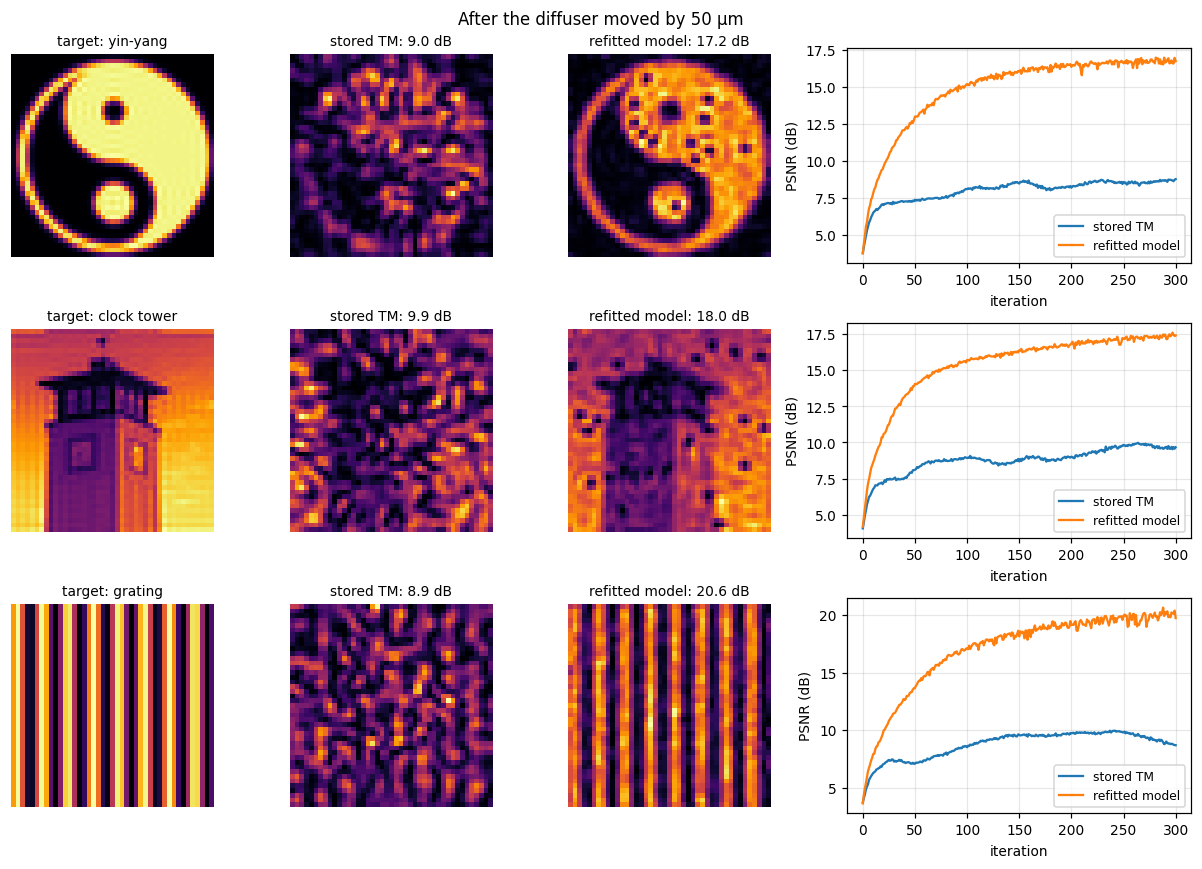

In [7]:
plot_results(moved, moved_adjoints, "After the diffuser moved by 50 µm")

## 5 · Training while the diffuser drifts slowly

So far the medium was static, or changed once before training. Here it drifts **during** training, following the
recipe of the manuscript (Methods, Fig. 4a–d, Supplementary Note 5A):

* **Drift.** On the bench, a phase ramp hidden from the model, whose frequency grows linearly with the iteration, walks
  the illumination across the diffuser; its output tilt and shift are calibrated and removed, so only the change of the
  medium seen by the beam remains. In the twin, the hidden screen moves under the beam by a distance that grows linearly
  with the iteration, until it has decorrelated to 0.3 with its starting state at the last iteration (`tw.Drift`),
  the stronger of the two drifts of Supplementary Note 5A.
* **Three runs** of the grating from the same starting model (ten probes): without drift; with drift and a **frozen**
  model, fitted before training and never refitted; and with the same drift and **refits**, in which two new random
  probes and the latest training frame are added every five iterations and the screen is refitted, warm-started, on the
  ten most recent fields. The training frames are measured anyway and cost no pattern.
* **Learning rate** 0.1 → 0.1 in the refitted run and 0.1 → 0.03 in the frozen and drift-free runs (Methods).
* **Score**: the PSNR of the mean image of the last ten iterations (main Fig. 4, at the weaker drift to 0.5: 19.5, 9.1
  and 17.6 dB on the bench,
  without drift, frozen and refitted), and the model accuracy during training, the correlation between each measured
  training frame and the model's prediction (Fig. 4d). With refits, recent training frames are part of the fit, so
  this accuracy sits slightly above that of the drift-free run.

The diffuser first goes back to its state of sections 1–3, and the model is the ten-probe model of section 1.

In [8]:
bench._true.D = D_start
DECORRELATION = 0.3
shift = tw.decorrelation_shift(D_start, DECORRELATION)
print(f"the screen decorrelates to {DECORRELATION} after a sideways shift of {shift * 1e6:.1f} µm (60 µm correlation length)")

target = targets["grating"]
loss = lambda I: tw.image_loss(I, target)
metric = lambda I: tw.psnr(I[tw.WIN], target)
drifts = {"no drift": None,
          "drift, frozen model": tw.Drift(bench, shift, ITERS),
          "drift, refits": tw.Drift(bench, shift, ITERS, refit=True, probes=(X_probe, Y_probe), rng=rng)}
drift_runs = {}
for name, drift in drifts.items():
    r = tw.train_in_situ(bench, model, loss, metric, iters=ITERS, final_reads=0,
                         lr_final=0.1 if name == "drift, refits" else 0.03, update=drift)
    if drift:
        drift.reset()
    r["mean_image"] = r["snaps"][-10:].mean(0)
    r["psnr_mean"] = tw.psnr(r["mean_image"], target)
    r["snaps"] = r["snaps"] * target.sum() / r["snaps"].sum(axis=(1, 2), keepdims=True)    # energy-normalised
    drift_runs[name] = r
    print(f"{name:20s} grating PSNR, mean image of the last 10 iterations: {r['psnr_mean']:5.2f} dB "
          f"(per frame {np.mean(r['curve'][-10:]):5.2f} dB); model accuracy at the end {r['accuracy'][-1]:.2f}")
refits = drifts["drift, refits"].refits
print(f"\n{len(refits)} refits, {2 * len(refits)} new probe patterns in all")

for name, r in drift_runs.items():
    others = {n: drift_runs[n]["curve"] for n in drift_runs if n != name}
    tw.save_gif(f"gifs/drift_grating_{name.replace(', ', '_').replace(' ', '_')}.gif", r["snaps"], r["curve"],
                "PSNR (dB)", f"grating, {name}", own_scale=False, extra_curves=others)

the screen decorrelates to 0.3 after a sideways shift of 51.5 µm (60 µm correlation length)


no drift             grating PSNR, mean image of the last 10 iterations: 22.33 dB (per frame 20.35 dB); model accuracy at the end 0.87


drift, frozen model  grating PSNR, mean image of the last 10 iterations:  7.59 dB (per frame  7.42 dB); model accuracy at the end 0.24


drift, refits        grating PSNR, mean image of the last 10 iterations: 21.37 dB (per frame 18.49 dB); model accuracy at the end 0.98

60 refits, 120 new probe patterns in all


**GIFs** (files in `gifs/`, linked; one frame per iteration):

| no drift | drift, frozen model | drift, refits |
|---|---|---|
| ![no drift](gifs/drift_grating_no_drift.gif) | ![frozen](gifs/drift_grating_drift_frozen_model.gif) | ![refits](gifs/drift_grating_drift_refits.gif) |

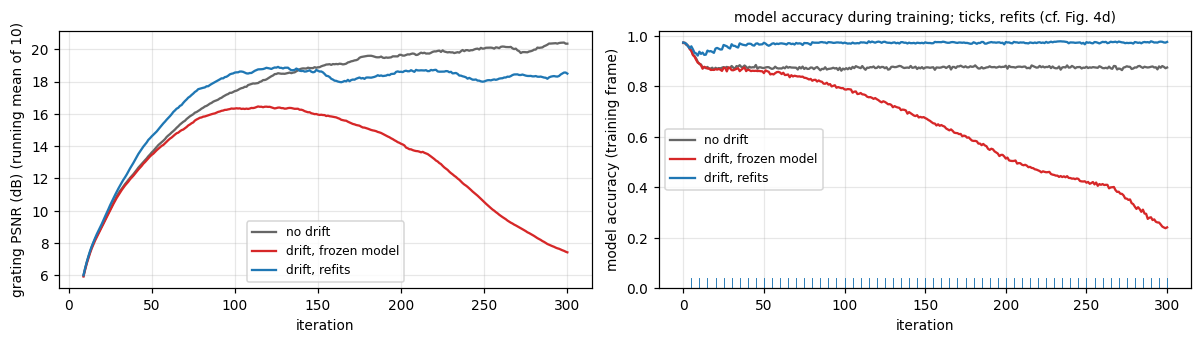

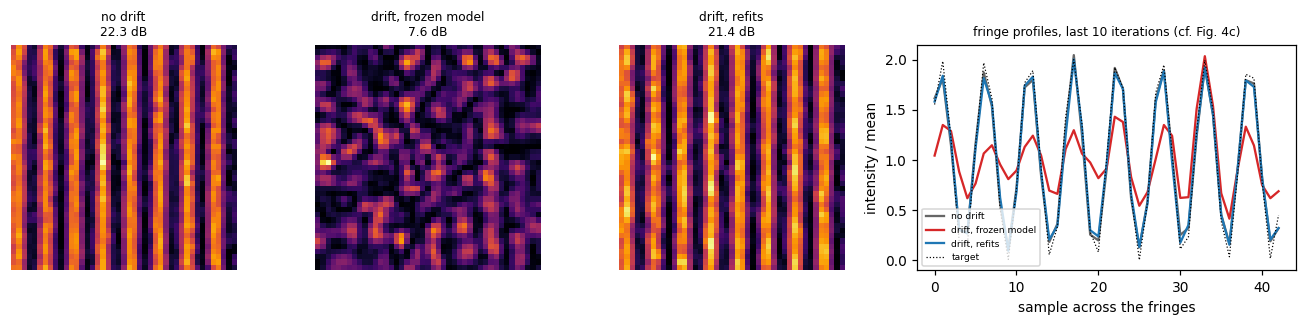

In [9]:
def plot_drift(runs, ylabel, smooth=10):
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
    for (name, r), color in zip(runs.items(), ["0.4", "C3", "C0"]):
        running = np.convolve(r["curve"], np.ones(smooth) / smooth, mode="valid")
        axs[0].plot(np.arange(smooth - 1, len(r["curve"])), running, color=color, label=name)
        axs[1].plot(r["accuracy"], color=color, label=name)
    for it in drifts["drift, refits"].refits:
        axs[1].axvline(it, ymin=0, ymax=0.04, color="C0", lw=0.6)
    axs[0].set_ylabel(f"{ylabel} (running mean of {smooth})"); axs[1].set_ylabel("model accuracy (training frame)")
    axs[1].set_ylim(0, 1.02); axs[1].set_title("model accuracy during training; ticks, refits (cf. Fig. 4d)")
    for ax in axs: ax.set_xlabel("iteration"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


plot_drift(drift_runs, "grating PSNR (dB)")

fig, axs = plt.subplots(1, 4, figsize=(12, 2.9), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.6]))
for ax, (name, r), color in zip(axs, drift_runs.items(), ["0.4", "C3", "C0"]):
    ax.imshow(r["mean_image"], cmap="inferno"); ax.set_title(f"{name}\n{r['psnr_mean']:.1f} dB", fontsize=8)
    ax.axis("off")
    profile = r["mean_image"].mean(0)
    axs[3].plot(profile / profile.mean(), color=color, label=name)
axs[3].plot(target.mean(0) / target.mean(), "k:", lw=0.8, label="target")
axs[3].set_xlabel("sample across the fringes"); axs[3].set_ylabel("intensity / mean")
axs[3].set_title("fringe profiles, last 10 iterations (cf. Fig. 4c)", fontsize=8); axs[3].legend(fontsize=6)
plt.tight_layout(); plt.show()

## Summary

SLM patterns spent on each adjoint and the PSNR of the mean image of the ten final reads.

In [10]:
print(f"{'adjoint':26s} {'new SLM patterns':>16s} " + " ".join(f"{t:>12s}" for t in targets))
for label, res, aname, p in [("model, 10 probes", runs, "model", 10), ("TM, 3N patterns", runs, "TM", 3072),
                             ("stored TM, after move", moved, "stored TM", 0),
                             ("model refitted, after move", moved, "refitted model", 10)]:
    print(f"{label:26s} {p:16,d} " + " ".join(f"{res[t, aname]['psnr_mean']:9.2f} dB" for t in targets))
print(f"\nSLM patterns displayed in this notebook: {bench.patterns:,}; runtime {time.time() - T_START:.0f} s")

adjoint                    new SLM patterns     yin-yang  clock tower      grating
model, 10 probes                         10     17.77 dB     17.73 dB     21.15 dB
TM, 3N patterns                       3,072     18.16 dB     18.26 dB     21.85 dB
stored TM, after move                     0      9.01 dB      9.93 dB      8.87 dB
model refitted, after move               10     17.23 dB     18.05 dB     20.57 dB

SLM patterns displayed in this notebook: 7,927; runtime 251 s


**Take-aways.** With ten probes and 300 iterations, the physical model forms the yin-yang, the clock tower and the
grating within 0.4–0.7 dB of a TM measured from 3,072 patterns, although the TM predicts held-out fields far better (0.99
against 0.86 on the window): the measured error field matters more than the accuracy of the model (on the bench, 17.2 and
16.7 dB against 18.1 and 17.1 dB, Fig. 2e,f). After the diffuser moves by 50 µm, the stored TM predicts held-out fields
with a model accuracy of only 0.39 and the images it trains stay near 9–10 dB, whereas ten new probes restore the model
(0.85) and the images (17–21 dB). When the diffuser drifts during training to a decorrelation of 0.3, the frozen model ages and the grating
falls to 7.6 dB (mean image of the last ten iterations), whereas refits from two probes and the latest training frame
every five iterations keep it at 21.4 dB, close to the 22.3 dB without drift (bench, at the weaker drift to 0.5: 9.1,
17.6 and 19.5 dB, Fig. 4b–d).
Averaging the ten final reads removes the frame-to-frame noise, so the mean image scores about 2–4 dB above a single read.